# Classification

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(torch.__version__)

2.12.0+cu126


In [2]:
# !nvidia-smi

# Architecture of a classification neural network

1. Input layer shape (in_features)
2. Hidden layers
3. Neurons per hidden layer
4. Output layer shape
5. Hidden layer activation: ReLU, GeLU
6. Output activation: Sigmoid, Softmax
7. Loss function: BCE, CrossEntropy
8. Optimizer: SGD, Adam

| Hyperparameter | Binary Classification | Multiclass Classification |
|---|---|---|
| **Input layer shape** (`in_features`) | Same as the number of features (e.g. 5 for age, sex, height, weight, and smoking status in heart disease prediction) | Same as binary classification |
| **Hidden layer(s)** | Problem-specific; minimum = 1, maximum = unlimited | Same as binary classification |
| **Neurons per hidden layer** | Problem-specific, generally 10 to 512 | Same as binary classification |
| **Output layer shape** (`out_features`) | 1 (one class or the other) | 1 per class (e.g. 3 for food, person, or dog photos) |
| **Hidden layer activation** | Usually ReLU (rectified linear unit), but there can be many others | Same as binary classification |
| **Output activation** | Sigmoid (`torch.sigmoid` in PyTorch) | Softmax (`torch.softmax` in PyTorch) |
| **Loss function** | Binary cross-entropy (`torch.nn.BCELoss` in PyTorch) | Cross-entropy (`torch.nn.CrossEntropyLoss` in PyTorch) |
| **Optimizer** | SGD (stochastic gradient descent), Adam (see `torch.optim` for more options) | Same as binary classification |

# 1. Data install and loader

## 1.1. EDA

In [3]:
from sklearn.datasets import make_circles
import random
# numpy, sklearn, matplotlib, pandas, datasets, tqdm, omegaconf, yaml, pytest, Hydra
# exp management: logging, wandb, mlflow
# file: pathlib, os, glob, json, csv, shutil
# NLP: transformers, sentenpiece, tokenizers, accelerate, peft
# Computer vision: torchvision, PIL, opencv-python2 (cv2), FFmpeg
# VLM: qwen-vl-utils, timm (CNN, ViT), TRL, open_clip
# Hardware (CPU, GPU): threading, multiprocessing
# typing, dataclass, pickle

random.seed(42)
n_samples = 1000
X, y = make_circles(n_samples, noise=0.03, random_state=42)
X, y

(array([[ 0.75424625,  0.23148074],
        [-0.75615888,  0.15325888],
        [-0.81539193,  0.17328203],
        ...,
        [-0.13690036, -0.81001183],
        [ 0.67036156, -0.76750154],
        [ 0.28105665,  0.96382443]], shape=(1000, 2)),
 array([1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
        0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
        0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1,
        1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1,
        1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
        1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1,
        0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
        1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
        0, 1

In [4]:
X[:5]

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       [-0.39373073,  0.69288277],
       [ 0.44220765, -0.89672343]])

In [5]:
circles = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    'label': y
})
print(circles.head(10))

         X1        X2  label
0  0.754246  0.231481      1
1 -0.756159  0.153259      1
2 -0.815392  0.173282      1
3 -0.393731  0.692883      1
4  0.442208 -0.896723      0
5 -0.479646  0.676435      1
6 -0.013648  0.803349      1
7  0.771513  0.147760      1
8 -0.169322 -0.793456      1
9 -0.121486  1.021509      0


In [6]:
circles.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

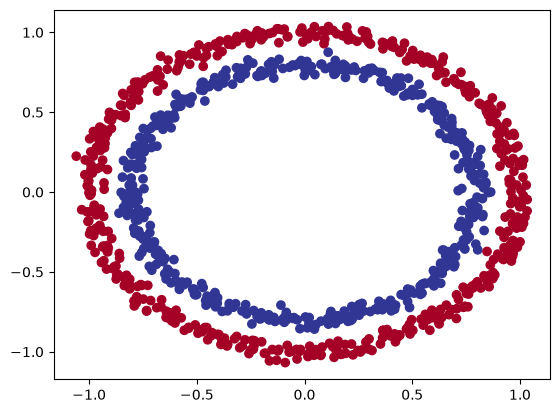

In [7]:
import matplotlib.pyplot as plt
plt.scatter(x=X[:, 0], 
            y=X[:, 1], 
            c=y, 
            cmap=plt.cm.RdYlBu)
plt.show()

## 1.2. Input, output shape

In [8]:
X.shape, y.shape

((1000, 2), (1000,))

In [9]:
# View the first example of features and labels
X_sample = X[0]
y_sample = y[0]
print(f"Values for one sample of X: {X_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {X_sample.shape} and the same for y: {y_sample.shape}")

Values for one sample of X: [0.75424625 0.23148074] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


## 1.3. Turn data into tensors 

In [10]:
# change to torch.float dtype
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [11]:
# Split into train, test set
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

(torch.Size([800, 2]),
 torch.Size([200, 2]),
 torch.Size([800]),
 torch.Size([200]))

Note: lack of data loader stage.

# 2. Buid model

## 2.1. Linear model

1. Setting up device agnostic code (so our model can run on CPU or GPU if it's available).
2. Constructing a model by subclassing nn.Module.
3. Defining a loss function and optimizer.
4. Creating a training loop (this'll be in the next section).

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

Create a model class
1. Subclasses nn.Module (almost all PyTorch models are subclasses of nn.Module).
2. Creates 2 nn.Linear layers in the constructor capable of handling the input and output shapes of X and y.
3. Defines a forward() method containing the forward pass computation of the model.
4. Instantiates the model class and sends it to the target device.

In [13]:
class NNClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=5)
        self.layer2 = nn.Linear(in_features=5, out_features=1)
    def forward(self, x):
        return self.layer2(self.layer1(x))

# Load model to device
model = NNClassification().to(device)
model

NNClassification(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [14]:
# load model
model_0 = NNClassification().to(device)
model_0

NNClassification(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

### Loss function and optimizer

In [15]:
# Loss function and optimizer
loss_fn = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

### Evaluation metrics

In [41]:
# def accuracy(pred, test):
#     if test.shape[0] == 0:
#         return 0
#     accuracy = np.sum(test==pred) / test.shape[0]
#     return accuracy

def accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_true)) * 100
    return acc

### Train model

In [17]:
# data to device
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

X_train.size(), y_train.size()

(torch.Size([800, 2]), torch.Size([800]))

In [18]:
y_pred = model_0(X_train)
y_pred
# loss_fn(y_pred, y_train)

tensor([[-0.3303],
        [-0.3239],
        [-1.1643],
        [-1.1367],
        [-0.8204],
        [-1.0793],
        [-0.9187],
        [-0.4256],
        [-1.0233],
        [-0.2171],
        [-1.0139],
        [-1.1361],
        [-0.2245],
        [-1.1218],
        [-0.8549],
        [-0.9556],
        [-0.6665],
        [-1.0707],
        [-0.4422],
        [-1.0362],
        [-0.3511],
        [-0.5096],
        [-0.1878],
        [-0.8327],
        [-1.0821],
        [-1.0914],
        [-0.7022],
        [-1.0490],
        [-0.9311],
        [-0.9231],
        [-0.5242],
        [-0.4297],
        [-0.5514],
        [-0.4014],
        [-0.1954],
        [-0.8620],
        [-0.2914],
        [-1.0634],
        [-0.8693],
        [-0.7239],
        [-0.9233],
        [-0.8305],
        [-0.9171],
        [-0.7659],
        [-0.8359],
        [-0.4601],
        [-1.1097],
        [-0.2951],
        [-0.9344],
        [-0.7300],
        [-1.1005],
        [-0.6718],
        [-0.

In [19]:
epochs = 1000

for epoch in range(epochs):
    model_0.train()
    # forward pass
    y_pred = model_0(X_train).squeeze(dim=1)

    # loss
    loss = loss_fn(y_pred, y_train)

    # zero grad
    optimizer.zero_grad()

    # backprop
    loss.backward()

    # update 
    optimizer.step()

    model_0.eval()
    with torch.inference_mode():
        # forward test data
        y_test_pred = model_0(X_test).squeeze(dim=1)
        # loss
        test_loss = loss_fn(y_test_pred, y_test)

        print(f"Epoch: {epoch} | Train loss: {loss} | Test Loss: {test_loss}")

Epoch: 0 | Train loss: 0.7606382369995117 | Test Loss: 0.7639519572257996
Epoch: 1 | Train loss: 0.759899914264679 | Test Loss: 0.7632166147232056
Epoch: 2 | Train loss: 0.7591702938079834 | Test Loss: 0.7624900937080383
Epoch: 3 | Train loss: 0.7584494352340698 | Test Loss: 0.7617721557617188
Epoch: 4 | Train loss: 0.7577371001243591 | Test Loss: 0.7610628604888916
Epoch: 5 | Train loss: 0.7570332288742065 | Test Loss: 0.7603619694709778
Epoch: 6 | Train loss: 0.7563377022743225 | Test Loss: 0.7596694827079773
Epoch: 7 | Train loss: 0.7556503415107727 | Test Loss: 0.7589852213859558
Epoch: 8 | Train loss: 0.7549711465835571 | Test Loss: 0.758309006690979
Epoch: 9 | Train loss: 0.7542999982833862 | Test Loss: 0.7576408982276917
Epoch: 10 | Train loss: 0.7536367774009705 | Test Loss: 0.7569807171821594
Epoch: 11 | Train loss: 0.7529812455177307 | Test Loss: 0.7563283443450928
Epoch: 12 | Train loss: 0.7523336410522461 | Test Loss: 0.7556837201118469
Epoch: 13 | Train loss: 0.75169348716

### Evaluate

In [20]:
import requests
from pathlib import Path 

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


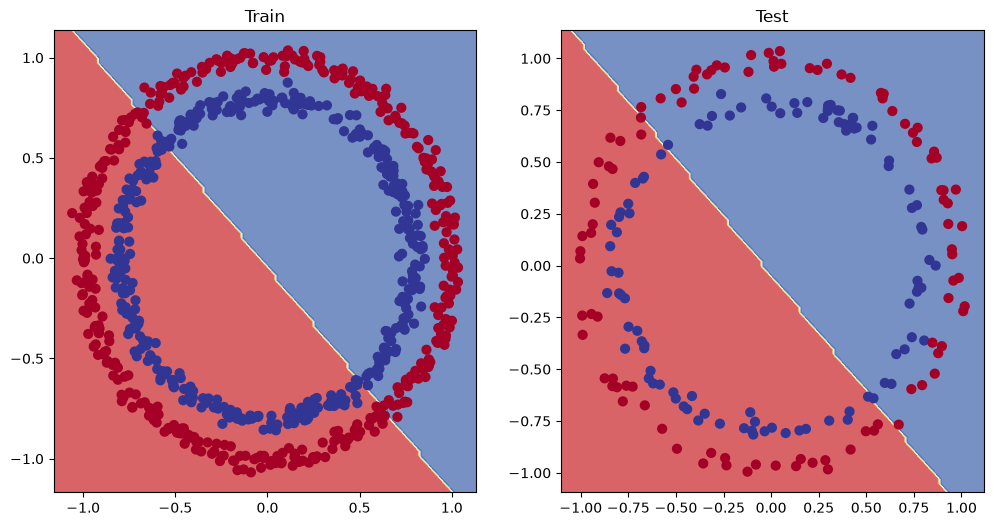

In [21]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

## 2.2. Model version 2

In [22]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=10)
        self.layer2 = nn.Linear(in_features=10, out_features=10)
        self.layer3 = nn.Linear(in_features=10, out_features=1)
    def forward(self, x):
        z = self.layer1(x)
        z = self.layer2(z)
        z = self.layer3(z)
        return z

In [23]:
model_v2 = CircleModelV1().to(device)
model_v2

CircleModelV1(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
)

In [24]:
# Loss and activation
loss_fn2 = nn.BCEWithLogitsLoss()
opimizer2 = torch.optim.SGD(model_v2.parameters(), lr = 0.1)

In [26]:
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

X_train.size(), y_train.size()

(torch.Size([800, 2]), torch.Size([800]))

In [29]:
y_logits = model_v2(X_train).squeeze()
y_pred = torch.round(torch.sigmoid(y_logits))
print(y_pred.shape)

torch.Size([800])


In [31]:
y_train.shape

torch.Size([800])

In [42]:
# Train model
epochs = 1000

for epoch in range(epochs):
    # forward
    y_logits = model_v2(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    # loss function
    loss = loss_fn2(y_logits, y_train)
    acc = accuracy(y_pred, y_train)

    # optimizer zero grad
    optimizer.zero_grad()

    # loss backward 
    loss.backward()

    optimizer.step()

    ### Testing
    model_v2.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_v2(X_test).squeeze()
      test_pred = torch.round(torch.sigmoid(test_logits)) # logits -> prediction probabilities -> prediction labels
      # 2. Calculate loss and accuracy
      test_loss = loss_fn(test_logits, y_test)
      test_acc = accuracy(y_true=y_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 100 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 200 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 300 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 400 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 500 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 600 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 700 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 800 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%
Epoch: 900 | Loss: 0.69465, Accuracy: 48.25% | Test Loss: 0.69169, Test Accuracy: 51.50%


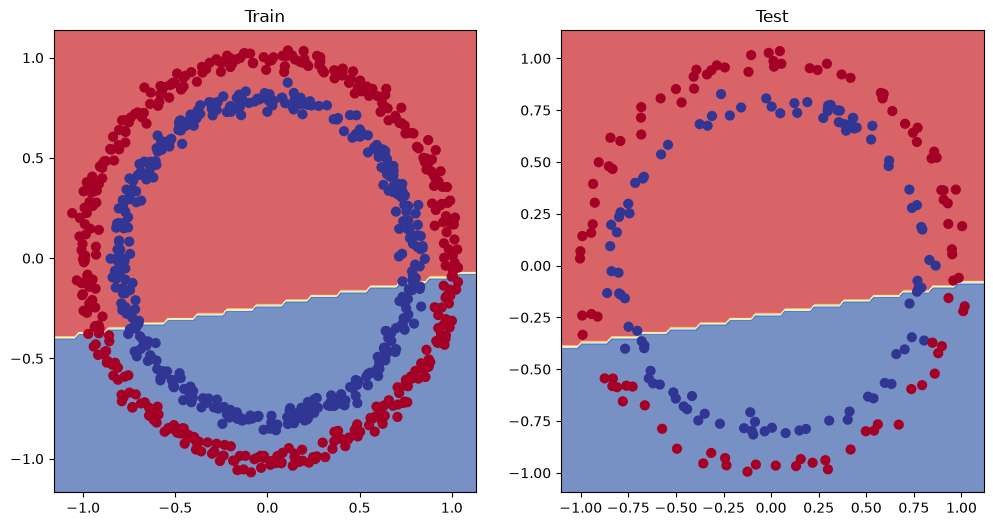

In [43]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_v2, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_v2, X_test, y_test)

## 2.3. Model version 3 (Non-Linear version)

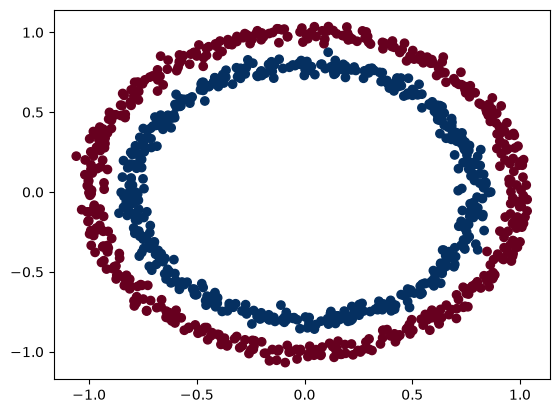

In [64]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples=1000,
    noise=0.03,
    random_state=42,
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu)
plt.show()

In [65]:
import torch
from sklearn.model_selection import train_test_split

# Turn data into tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.2,
                                                    random_state=42
)

X_train[:5], y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

In [73]:
class CircleModelV3(nn.Module):
    '''
    Attributes: layers
    Function: forward()
    '''
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=10)
        self.layer2 = nn.Linear(in_features=10, out_features=10)
        self.layer3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        out1 = self.layer1(x)
        out2 = self.layer2(out1)
        out3 = self.relu(out2)
        out = self.layer3(out3)
        return out

model_v3 = CircleModelV3()
model_v3

CircleModelV3(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [74]:
# Setup loss and optimizer 
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_v3.parameters(), lr=0.1)

In [75]:
torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
    # forward pass
    y_logits = model_v3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    # Calculate loss function
    loss = loss_fn(y_logits, y_train)
    acc = accuracy(y_true=y_train, 
                    y_pred=y_pred)

    # Optimizer 
    optimizer.zero_grad()

    # Loss backward 
    loss.backward()

    # Optimizer step
    optimizer.step()

    ### Testing
    model_v3.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_v3(X_test).squeeze()
      test_pred = torch.round(torch.sigmoid(test_logits)) # logits -> prediction probabilities -> prediction labels
      # 2. Calculate loss and accuracy
      test_loss = loss_fn(test_logits, y_test)
      test_acc = accuracy(y_true=y_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 100 == 0:    
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69833, Accuracy: 50.00% | Test Loss: 0.69863, Test Accuracy: 49.00%
Epoch: 100 | Loss: 0.69289, Accuracy: 50.88% | Test Loss: 0.69411, Test Accuracy: 47.00%
Epoch: 200 | Loss: 0.69015, Accuracy: 53.37% | Test Loss: 0.69141, Test Accuracy: 50.00%
Epoch: 300 | Loss: 0.68762, Accuracy: 56.62% | Test Loss: 0.68828, Test Accuracy: 55.00%
Epoch: 400 | Loss: 0.68469, Accuracy: 60.00% | Test Loss: 0.68469, Test Accuracy: 61.00%
Epoch: 500 | Loss: 0.67985, Accuracy: 56.00% | Test Loss: 0.67890, Test Accuracy: 60.50%
Epoch: 600 | Loss: 0.67280, Accuracy: 56.00% | Test Loss: 0.67176, Test Accuracy: 60.50%
Epoch: 700 | Loss: 0.66304, Accuracy: 64.50% | Test Loss: 0.66452, Test Accuracy: 65.00%
Epoch: 800 | Loss: 0.64710, Accuracy: 74.12% | Test Loss: 0.65300, Test Accuracy: 71.50%
Epoch: 900 | Loss: 0.62182, Accuracy: 81.62% | Test Loss: 0.63241, Test Accuracy: 78.00%


In [76]:
# Make predictions
model_v3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_v3(X_test))).squeeze()
y_preds[:10], y[:10] # want preds in same format as truth labels

(tensor([1., 1., 1., 0., 1., 1., 0., 0., 1., 0.]),
 tensor([1., 1., 1., 1., 0., 1., 1., 1., 1., 0.]))

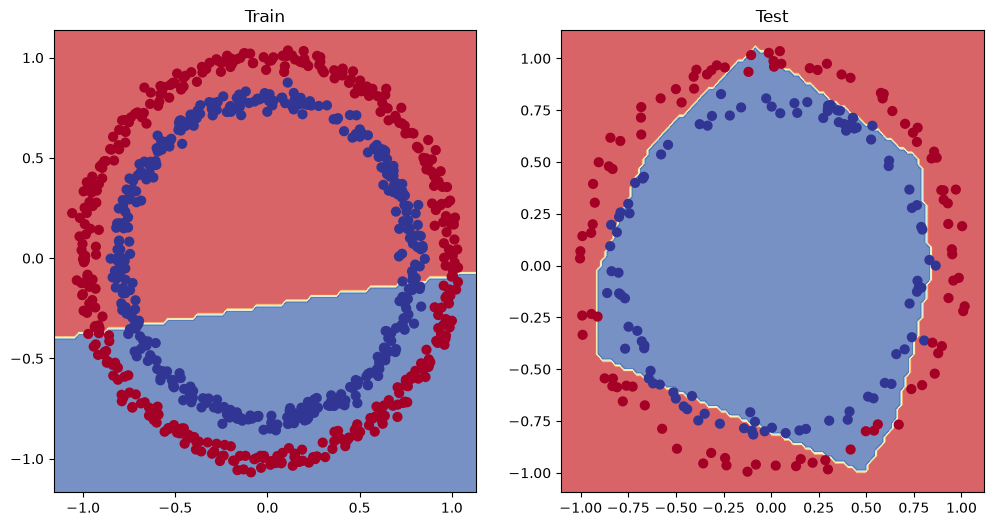

In [77]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_v2, X_train, y_train) # model_1 = no non-linearity
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_v3, X_test, y_test) # model_3 = has non-linearity

In [79]:
# Create a toy tensor (similar to the data going into our model(s))
A = torch.arange(-10, 10, 1, dtype=torch.float32)
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])